# Simple RNN for SMS Text Classification

**Problem statement:** Predict whether an SMS message is **ham** (legitimate) or
**spam** using the [SMS Spam Collection dataset](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset).
Keep only text and label; tokenize with Keras `Tokenizer(num_words=5000)`;
pad/truncate every sequence to exactly 50 tokens; build
`Embedding(5000, 32) → SimpleRNN(32) → Dense(1, activation="sigmoid")`;
train for exactly **5 epochs** and report held-out test accuracy.

**Day-1 rubric evidence:** This revised submission also includes dataframe
inspection, missingness/duplicate/anomaly checks, four labelled EDA charts,
four engineered dataframe features with rationale, and five data-grounded
insights. Engineered features are for EDA; the RNN input remains text only.

**Target:** label (`ham=0`, `spam=1`). **Input feature:** the SMS text only.
This dataset has two classes, so sigmoid and binary cross-entropy are used.
For a dataset with more than two classes, use `Dense(n_classes, activation="softmax")`
and sparse categorical cross-entropy with integer labels instead.

Run all cells in order. On Kaggle, attach `uciml/sms-spam-collection-dataset`.
Locally/Colab, upload `spam.csv` beside this notebook or let KaggleHub download it.
If dependencies are missing, run `%pip install tensorflow pandas scikit-learn matplotlib kagglehub` first.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["OMP_NUM_THREADS"] = "1"

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

# Small CPU thread pools also work on hosted notebook runtimes.
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
SEED = 42
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__, "pandas:", pd.__version__, "scikit-learn:", sklearn.__version__)
output_dir = Path("simple_rnn_results")
output_dir.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

TensorFlow: 2.20.0
NumPy: 2.2.6 pandas: 3.0.6 scikit-learn: 1.9.1


## 1. Load only text and label

The CSV uses `v1` for the label and `v2` for the text. Drop the unrelated empty
columns by selecting these two columns explicitly. Remove missing/empty rows
and exact duplicate messages before splitting, so identical text cannot appear
in both training and testing. No stemming, TF-IDF, or extra input features are used.

In [2]:
candidates = [Path("spam.csv"), Path("data/spam.csv"), Path("data/sms_spam/spam.csv")]
if Path("/kaggle/input").exists():
    candidates = sorted(Path("/kaggle/input").rglob("spam.csv")) + candidates
csv_path = next((path for path in candidates if path.is_file()), None)
if csv_path is None:
    import kagglehub
    dataset_dir = Path(kagglehub.dataset_download("uciml/sms-spam-collection-dataset"))
    csv_path = next(dataset_dir.rglob("spam.csv"))

raw = pd.read_csv(csv_path, encoding="latin-1")
df = raw[["v2", "v1"]].rename(columns={"v2": "text", "v1": "label"}).copy()
raw_rows = len(df)
print("Raw CSV shape:", raw.shape)
print("Retained dataframe shape:", df.shape)
display(df.head())
print("Column dtypes:")
print(df.dtypes)
print("Dataframe info:")
df.info()
print("Describe all retained columns:")
display(df.describe(include="all"))
missing_before = df.isna().sum()
blank_text_rows = int(df["text"].fillna("").str.strip().eq("").sum())
print("Missing values before cleaning:")
print(missing_before)
print("Blank text rows:", blank_text_rows)
print("Original label values:", sorted(df["label"].dropna().unique()))
print("Exact duplicate text rows before cleaning:", int(df.duplicated(subset=["text"]).sum()))

Raw CSV shape: (5572, 5)
Retained dataframe shape: (5572, 2)


,text,label
0,"Go until jurong point, crazy.. Available only ...",ham
1,Ok lar... Joking wif u oni...,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,spam
3,U dun say so early hor... U c already then say...,ham
4,"Nah I don't think he goes to usf, he lives aro...",ham


Column dtypes:
text     str
label    str
dtype: object
Dataframe info:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    5572 non-null   str  
 1   label   5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB
Describe all retained columns:


,text,label
count,5572,5572
unique,5169,2
top,"Sorry, I'll call later",ham
freq,30,4825


Missing values before cleaning:
text     0
label    0
dtype: int64
Blank text rows: 0
Original label values: ['ham', 'spam']
Exact duplicate text rows before cleaning: 403


### R1 — Interpret the initial inspection

The CSV has **5,572 rows and 5 columns**, but only **2 columns** are retained:
`text` and `label`. Both contain strings before label encoding; `info()` shows
5,572 non-null entries in each, and `describe(include="all")` summarizes their
unique values and most frequent values. There are **0 missing values** in these
two columns and **0 blank messages**; labels are exactly `ham` and `spam`.
There are **403 duplicate texts**, so they are removed before the split to
avoid identical messages in training and testing. The three unrelated CSV
columns are excluded rather than imputed.

In [3]:
df = df.dropna(subset=["text", "label"])
df = df[df["text"].str.strip().ne("")].copy()
assert df.groupby("text")["label"].nunique().max() == 1, "Conflicting labels for identical text"
duplicates_removed = int(df.duplicated(subset=["text"]).sum())
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)
label_mapping = {"ham": 0, "spam": 1}
assert set(df["label"]) == set(label_mapping)
df["label"] = df["label"].map(label_mapping).astype("int32")
assert df.columns.tolist() == ["text", "label"]
print(f"Raw rows: {raw_rows}; duplicate messages removed: {duplicates_removed}; retained: {len(df)}")
print("Label mapping:", label_mapping)
print(df["label"].value_counts().rename(index={0: "ham", 1: "spam"}))
df.head()

Raw rows: 5572; duplicate messages removed: 403; retained: 5169
Label mapping: {'ham': 0, 'spam': 1}
label
ham     4516
spam     653
Name: count, dtype: int64


,text,label
0,"Go until jurong point, crazy.. Available only ...",0
1,Ok lar... Joking wif u oni...,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,U dun say so early hor... U c already then say...,0
4,"Nah I don't think he goes to usf, he lives aro...",0


### R4 — Engineer and inspect interpretable text features

`eda_df` is a separate dataframe copied from the cleaned `text`/`label` data.
It contains four explicit engineered features with these rationales:

| Feature | Definition | Rationale |
|---|---|---|
| `message_length` | Number of characters, including spaces | Measures message size and supports the length-anomaly check. |
| `word_count` | Number of whitespace-separated words | Measures verbosity and complements character length. |
| `has_url` | 1 if `http://`, `https://`, or `www.` occurs; otherwise 0 | Flags an explicit web-link pattern that may be associated with spam. |
| `uppercase_ratio` | Uppercase letters divided by all alphabetic letters; 0 when no letters exist | Measures emphasis without simply counting longer messages as more emphatic. |

These are descriptive features, not additional RNN inputs. The original `df`
keeps exactly `text` and `label`; model training below selects `df["text"]`.
Whitespace word counts are not identical to Keras tokenizer sequence lengths.

In [4]:
eda_df = df.copy()
eda_df["label"] = eda_df["label"].map({0: "ham", 1: "spam"})
eda_df["message_length"] = eda_df["text"].str.len()
eda_df["word_count"] = eda_df["text"].str.split().str.len()
eda_df["has_url"] = eda_df["text"].str.contains(r"https?://|www\.", case=False, regex=True).astype("int32")
eda_df["uppercase_ratio"] = eda_df["text"].apply(
    lambda text: sum(char.isupper() for char in text) / max(1, sum(char.isalpha() for char in text))
)
feature_columns = ["message_length", "word_count", "has_url", "uppercase_ratio"]
assert df.columns.tolist() == ["text", "label"]
assert eda_df[feature_columns].notna().all().all()
assert eda_df["message_length"].gt(0).all() and eda_df["word_count"].gt(0).all()
assert eda_df["uppercase_ratio"].between(0, 1).all()
print("Engineered feature sample:")
display(eda_df[["label"] + feature_columns].head(10))
print("Engineered feature dtypes:")
print(eda_df[feature_columns].dtypes)
print("Feature statistics:")
display(eda_df[feature_columns].describe())
feature_by_label = eda_df.groupby("label").agg(
    messages=("text", "size"),
    median_characters=("message_length", "median"),
    median_words=("word_count", "median"),
    messages_with_url=("has_url", "sum"),
    mean_uppercase_ratio=("uppercase_ratio", "mean"),
)
print("Feature summary by label:")
display(feature_by_label)

Engineered feature sample:


,label,message_length,word_count,has_url,uppercase_ratio
0,ham,111,20,0,0.036145
1,ham,29,6,0,0.111111
2,spam,155,28,0,0.103093
3,ham,49,11,0,0.060606
4,ham,61,13,0,0.042553
5,spam,148,32,0,0.067308
6,ham,77,16,0,0.033333
7,ham,160,26,0,0.078125
8,spam,158,26,0,0.112150
9,spam,154,29,0,0.126126


Engineered feature dtypes:
message_length       int64
word_count           int64
has_url              int32
uppercase_ratio    float64
dtype: object
Feature statistics:


,message_length,word_count,has_url,uppercase_ratio
count,5169.000000,5169.000000,5169.000000,5169.000000
mean,78.977945,15.340685,0.017605,0.089299
std,58.236293,11.068488,0.131523,0.150500
min,2.000000,1.000000,0.000000,0.000000
25%,36.000000,7.000000,0.000000,0.033333
50%,60.000000,12.000000,0.000000,0.050000
75%,117.000000,22.000000,0.000000,0.081081
max,910.000000,171.000000,1.000000,1.000000


Feature summary by label:


,messages,median_characters,median_words,messages_with_url,mean_uppercase_ratio
label,,,,,
ham,4516,52.0,11.0,1,0.078340
spam,653,149.0,25.0,90,0.165089


### R2 — Check outliers and obvious anomalies

Apply the 1.5 × IQR rule to character length and inspect the longest messages.
Also check for zero-length/zero-word messages, conflicting labels for identical
text, invalid feature values, and missing values. IQR flags are candidates for
inspection; an extreme length alone does not establish that a message is invalid.

In [5]:
q1, q3 = eda_df["message_length"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
length_outlier_mask = ~eda_df["message_length"].between(lower_bound, upper_bound)
outlier_count = int(length_outlier_mask.sum())
print(f"Character-length Q1={q1:.1f}, Q3={q3:.1f}, IQR={iqr:.1f}")
print(f"IQR bounds: [{lower_bound:.1f}, {upper_bound:.1f}]")
print(f"Length outliers: {outlier_count}/{len(eda_df)} ({outlier_count / len(eda_df):.2%})")
print("Character-length range:", eda_df["message_length"].min(), "to", eda_df["message_length"].max())
print("Zero-length messages:", int(eda_df["message_length"].eq(0).sum()))
print("Zero-word messages:", int(eda_df["word_count"].eq(0).sum()))
print("Conflicting labels per identical text:", int(eda_df.groupby("text")["label"].nunique().gt(1).sum()))
print("Missing engineered feature values:", int(eda_df[feature_columns].isna().sum().sum()))
print("Longest five messages (inspect their text and lengths):")
with pd.option_context("display.max_colwidth", 1000):
    display(eda_df.nlargest(5, "message_length")[["text", "label", "message_length", "word_count"]])

Character-length Q1=36.0, Q3=117.0, IQR=81.0
IQR bounds: [-85.5, 238.5]
Length outliers: 66/5169 (1.28%)
Character-length range: 2 to 910
Zero-length messages: 0
Zero-word messages: 0
Conflicting labels per identical text: 0
Missing engineered feature values: 0
Longest five messages (inspect their text and lengths):


,text,label,message_length,word_count
1059,For me the love should start with attraction.i should feel that I need her every time around me.she should be the first thing which comes in my thoughts.I would start the day and end it with her.she should be there every time I dream.love will be then when my every breath has her name.my life should happen around her.my life will be named to her.I would cry for her.will give all my happiness and take all her sorrows.I will be ready to fight with anyone for her.I will be in love when I will be doing the craziest things for her.love will be when I don't have to proove anyone that my girl is the most beautiful lady on the whole planet.I will always be singing praises for her.love will be when I start up making chicken curry and end up makiing sambar.life will be the most beautiful then.will get every morning and thank god for the day because she is with me.I would like to say a lot..will tell later..,ham,910,171
1800,"The last thing i ever wanted to do was hurt you. And i didn't think it would have. You'd laugh, be embarassed, delete the tag and keep going. But as far as i knew, it wasn't even up. The fact that you even felt like i would do it to hurt you shows you really don't know me at all. It was messy wednesday, but it wasn't bad. The problem i have with it is you HAVE the time to clean it, but you choose not to. You skype, you take pictures, you sleep, you want to go out. I don't mind a few things here and there, but when you don't make the bed, when you throw laundry on top of it, when i can't have a friend in the house because i'm embarassed that there's underwear and bras strewn on the bed, pillows on the floor, that's something else. You used to be good about at least making the bed.",ham,790,162
2333,"Indians r poor but India is not a poor country. Says one of the swiss bank directors. He says that \ &lt;#&gt; lac crore\"" of Indian money is deposited in swiss banks which can be used for 'taxless' budget for &lt;#&gt; yrs. Can give &lt;#&gt; crore jobs to all Indians. From any village to Delhi 4 lane roads. Forever free power suply to more than &lt;#&gt; social projects. Every citizen can get monthly &lt;#&gt; /- for &lt;#&gt; yrs. No need of World Bank &amp; IMF loan. Think how our money is blocked by rich politicians. We have full rights against corrupt politicians. Itna forward karo ki pura INDIA padhe.g.m.\""""",ham,632,109
1528,How to Make a girl Happy? It's not at all difficult to make girls happy. U only need to be... 1. A friend 2. Companion 3. Lover 4. Chef . . . &lt;#&gt; . Good listener &lt;#&gt; . Organizer &lt;#&gt; . Good boyfriend &lt;#&gt; . Very clean &lt;#&gt; . Sympathetic &lt;#&gt; . Athletic &lt;#&gt; . Warm . . . &lt;#&gt; . Courageous &lt;#&gt; . Determined &lt;#&gt; . True &lt;#&gt; . Dependable &lt;#&gt; . Intelligent . . . &lt;#&gt; . Psychologist &lt;#&gt; . Pest exterminator &lt;#&gt; . Psychiatrist &lt;#&gt; . Healer . . &lt;#&gt; . Stylist &lt;#&gt; . Driver . . Aaniye pudunga venaam..,ham,611,103
2075,"Sad story of a Man - Last week was my b'day. My Wife did'nt wish me. My Parents forgot n so did my Kids . I went to work. Even my Colleagues did not wish. As I entered my cabin my PA said, '' Happy B'day Boss !!''. I felt special. She askd me 4 lunch. After lunch she invited me to her apartment. We went there. She said,'' do u mind if I go into the bedroom for a minute ? '' ''OK'', I sed in a sexy mood. She came out 5 minuts latr wid a cake...n My Wife, My Parents, My Kidz, My Friends n My Colleagues. All screaming.. SURPRISE !! and I was waiting on the sofa.. ... ..... ' NAKED...!",ham,588,125


**Outlier treatment:** Q1 is **36** characters, Q3 is **117**, and the upper
IQR bound is **238.5**. There are **66 flagged messages (1.28%)**; character
lengths range from **2 to 910**. No empty messages, zero-word messages,
conflicting labels, or missing engineered features remain. The longest examples
contain message text, so length alone gives no defensible reason to delete them.
**Retain all 66 length outliers and do not cap character-length features.** Long
messages can contain useful ham/spam signals, and deletion could distort the
observed distribution. Only model inputs are truncated, using the assignment's
fixed **50-token** rule; this is separate from character-length outlier handling.
The full EDA is descriptive and does not change the fixed model or holdout policy.

### R3 — Four labelled exploratory visualizations

All charts use the **5,169 cleaned unique messages**. Blue denotes ham and
orange denotes spam in class comparisons. Counts and character lengths are
labelled with units; the association chart gives each bin's sample size.

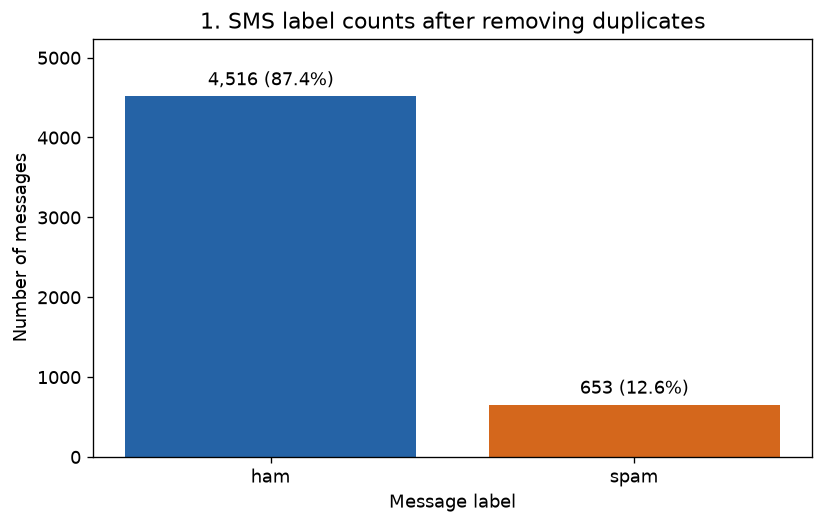

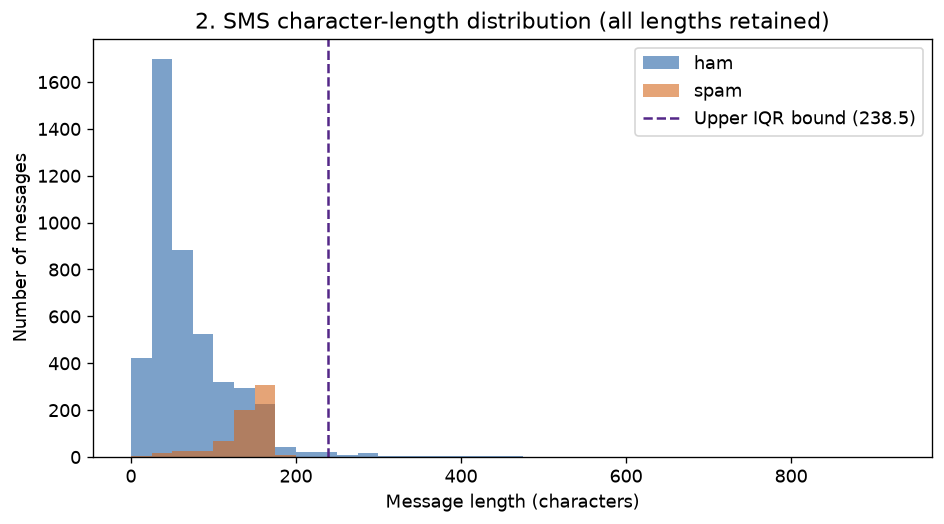

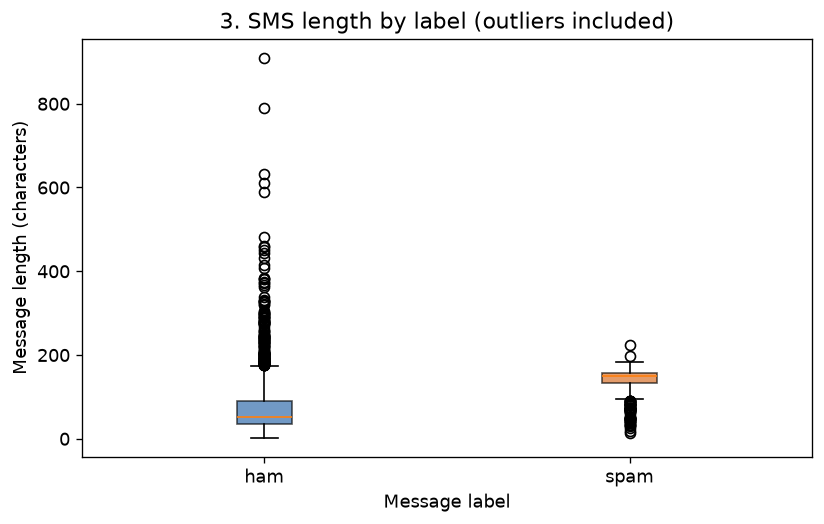

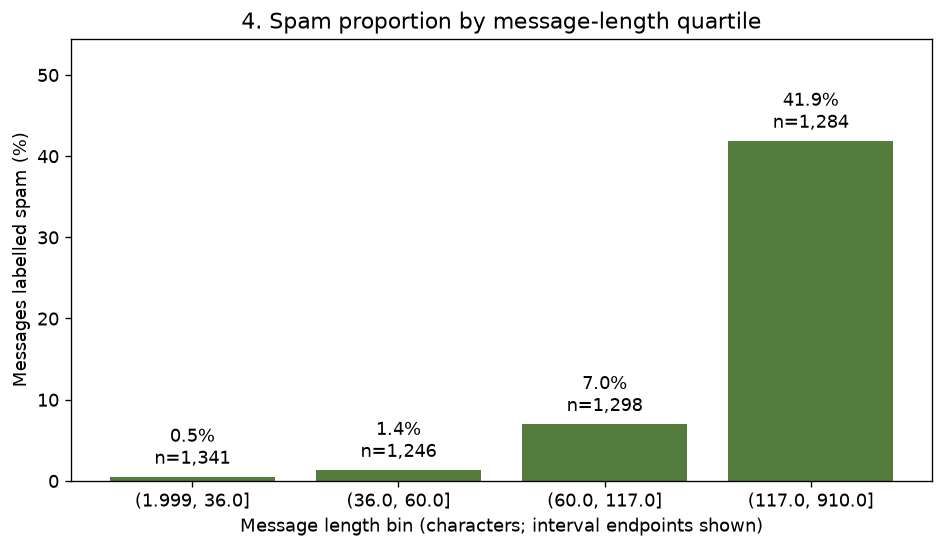

,messages,spam_rate
length_bin,,
"(1.999, 36.0]",1341,0.005220
"(36.0, 60.0]",1246,0.013644
"(60.0, 117.0]",1298,0.070108
"(117.0, 910.0]",1284,0.419003


In [6]:
label_order = ["ham", "spam"]
colors = {"ham": "#2563a6", "spam": "#d4671c"}

# Chart 1: label count plot.
counts = eda_df["label"].value_counts().reindex(label_order)
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(counts.index, counts.values, color=[colors[label] for label in label_order])
ax.bar_label(bars, labels=[f"{count:,} ({count / len(eda_df):.1%})" for count in counts], padding=4)
ax.set(title="1. SMS label counts after removing duplicates", xlabel="Message label", ylabel="Number of messages")
ax.set_ylim(0, counts.max() * 1.16)
fig.tight_layout()
fig.savefig(output_dir / "01_label_counts.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# Chart 2: full message-length histogram; extreme values remain visible.
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(0, eda_df["message_length"].max() + 26, 25)
for label in label_order:
    ax.hist(eda_df.loc[eda_df["label"].eq(label), "message_length"], bins=bins,
            alpha=0.60, color=colors[label], label=label)
ax.axvline(upper_bound, color="#542788", linestyle="--", label=f"Upper IQR bound ({upper_bound:.1f})")
ax.set(title="2. SMS character-length distribution (all lengths retained)", xlabel="Message length (characters)", ylabel="Number of messages")
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "02_length_histogram.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# Chart 3: length by label, with outlier points shown.
fig, ax = plt.subplots(figsize=(7, 4.5))
box = ax.boxplot([eda_df.loc[eda_df["label"].eq(label), "message_length"] for label in label_order],
                 patch_artist=True, showfliers=True)
for patch, label in zip(box["boxes"], label_order):
    patch.set_facecolor(colors[label])
    patch.set_alpha(0.65)
ax.set_xticks([1, 2])
ax.set_xticklabels(label_order)
ax.set(title="3. SMS length by label (outliers included)", xlabel="Message label", ylabel="Message length (characters)")
fig.tight_layout()
fig.savefig(output_dir / "03_length_by_label_boxplot.png", bbox_inches="tight")
plt.show()
plt.close(fig)

# Chart 4: descriptive length-label association, using quantile bins.
length_bins = pd.qcut(eda_df["message_length"], q=4, duplicates="drop")
association = eda_df.assign(length_bin=length_bins, is_spam=eda_df["label"].eq("spam").astype(int))
association = association.groupby("length_bin", observed=True).agg(
    messages=("is_spam", "size"), spam_rate=("is_spam", "mean")
)
fig, ax = plt.subplots(figsize=(8, 4.7))
bars = ax.bar(association.index.astype(str), association["spam_rate"] * 100, color="#547c3c")
ax.bar_label(bars, labels=[f"{row.spam_rate:.1%}\nn={int(row.messages):,}" for row in association.itertuples()], padding=4)
ax.set(title="4. Spam proportion by message-length quartile", xlabel="Message length bin (characters; interval endpoints shown)", ylabel="Messages labelled spam (%)")
ax.set_ylim(0, max(5, association["spam_rate"].max() * 100 * 1.3))
fig.tight_layout()
fig.savefig(output_dir / "04_length_label_association.png", bbox_inches="tight")
plt.show()
plt.close(fig)
display(association)

eda_summary = {
    "raw_shape": list(raw.shape), "retained_input_columns": df.columns.tolist(),
    "missing_text_or_label_before_cleaning": int(missing_before.sum()),
    "blank_text_rows_before_cleaning": blank_text_rows,
    "duplicates_removed": duplicates_removed, "clean_rows": len(eda_df),
    "class_counts": {label: int(counts[label]) for label in label_order},
    "engineered_features": feature_columns,
    "length_q1": float(q1), "length_q3": float(q3), "length_iqr": float(iqr),
    "length_upper_iqr_bound": float(upper_bound), "length_outliers": outlier_count,
    "length_min": int(eda_df["message_length"].min()), "length_max": int(eda_df["message_length"].max()),
    "outlier_policy": "Retain all messages; do not cap character features. Model inputs use fixed maxlen=50 tokens.",
    "chart_files": ["01_label_counts.png", "02_length_histogram.png", "03_length_by_label_boxplot.png", "04_length_label_association.png"],
}
(output_dir / "eda_summary.json").write_text(json.dumps(eda_summary, indent=2))
feature_by_label.to_csv(output_dir / "features_by_label.csv")
association.to_csv(output_dir / "length_label_association.csv")
assert counts.to_dict() == {"ham": 4516, "spam": 653}
assert q1 == 36 and q3 == 117 and outlier_count == 66
assert feature_by_label.loc["ham", "median_characters"] == 52
assert feature_by_label.loc["spam", "median_characters"] == 149
assert feature_by_label.loc["ham", "median_words"] == 11
assert feature_by_label.loc["spam", "median_words"] == 25
assert feature_by_label.loc["ham", "messages_with_url"] == 1
assert feature_by_label.loc["spam", "messages_with_url"] == 90

### R5 — Five data-grounded Day-1 insights

- **Cleaning:** Of **5,572** source messages, **403 exact duplicate texts (7.23%)** are removed, leaving **5,169** unique messages. Initial inspection finds **0 missing text/label values and 0 blank messages**, so no text or label imputation is needed.
- **Class balance (chart 1):** The cleaned data has **4,516 ham (87.37%)** and **653 spam (12.63%)** messages. This imbalance motivates a stratified split and reporting a majority-class baseline alongside accuracy.
- **Length and verbosity (charts 2–4; feature table):** Spam has median length **149 characters / 25 words**, compared with **52 characters / 11 words** for ham. Chart 4 shows a spam rate of **0.52%** in the shortest quartile versus **41.90%** in the longest. The boxplots still show overlap; length alone is not a sufficient classifier or a causal explanation.
- **Length anomalies (chart 2 and IQR check):** **66 messages (1.28%)** exceed the **238.5-character** upper IQR bound; the longest has **910 characters**. These messages are retained as plausible text rather than automatically deleted, while the model separately enforces the required **50-token** maximum.
- **URL feature:** The explicit `http(s)://` / `www.` pattern occurs in **90 of 653 spam messages (13.78%)** and **1 of 4,516 ham messages (0.02%)**. It is associated with spam in this dataset but misses **563 spam messages**, so absence of a detected URL does not establish that a message is ham.

These figures describe this dataset; the fixed RNN is not selected or tuned from
the EDA patterns. The feature and outlier assertions above check the counts used
in these bullets against the data loaded in this run.

## 2. Split before learning the vocabulary

Use a reproducible, stratified 80% training / 20% test split. Stratification
preserves the ham/spam proportions; the test set is used only after five epochs.
The vocabulary is learned from training text only.

In [7]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.20, random_state=SEED, stratify=df["label"]
)
assert set(X_train_text).isdisjoint(set(X_test_text))
print(f"Training messages: {len(X_train_text)}; test messages: {len(X_test_text)}")

tokenizer = Tokenizer(num_words=5000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)
train_sequences = tokenizer.texts_to_sequences(X_train_text)
test_sequences = tokenizer.texts_to_sequences(X_test_text)

Training messages: 4135; test messages: 1034


## 3. Make every input exactly 50 tokens

The same `maxlen=50` handles every row: shorter sequences get zeros at the
beginning and longer sequences keep their last 50 tokens. Keras reserves index
0 for padding; `num_words=5000` retains word indices below 5000, including the
out-of-vocabulary token at index 1, so all indices fit the 5,000-row embedding.

In [8]:
X_train = pad_sequences(train_sequences, maxlen=50, padding="pre", truncating="pre")
X_test = pad_sequences(test_sequences, maxlen=50, padding="pre", truncating="pre")
y_train = y_train.to_numpy(dtype="int32")
y_test = y_test.to_numpy(dtype="int32")
assert X_train.shape == (len(y_train), 50)
assert X_test.shape == (len(y_test), 50)
assert 0 <= X_train.min() and X_train.max() < 5000
assert 0 <= X_test.min() and X_test.max() < 5000
print("Training shape:", X_train.shape, "Test shape:", X_test.shape)
print("First test sequence length before padding:", len(test_sequences[0]))
print("First test input after padding/truncation:", X_test[0])

Training shape: (4135, 50) Test shape: (1034, 50)
First test sequence length before padding: 31
First test input after padding/truncation: [   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0   59  204   13   71    2   51    3  234   23
    8  297    4    5  123   66  748   16  553  335    8 1671    4   22
   13  190  280  177    2   71    4  455]


## 4. Build the exact requested model

Each token becomes a 32-value embedding. The 32-unit SimpleRNN reads the
50-token sequence and passes its final state to a single sigmoid output,
which estimates the probability of spam. There are no additional model layers.

In [9]:
model = Sequential([
    Embedding(5000, 32),
    SimpleRNN(32),
    Dense(1, activation="sigmoid")
])
model.build(input_shape=(None, 50))
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()
assert [type(layer).__name__ for layer in model.layers] == ["Embedding", "SimpleRNN", "Dense"]
assert model.count_params() == 162113

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,113 (633.25 KB)

 Trainable params: 162,113 (633.25 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Train for exactly five epochs

Batch size is 64. The TensorFlow datasets below only batch/shuffle the inputs;
their small thread pools keep CPU execution reliable. No early stopping or test
set validation is used, and there is no tuning against test results.

In [10]:
options = tf.data.Options()
options.threading.private_threadpool_size = 1
options.threading.max_intra_op_parallelism = 1
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.shuffle(len(X_train), seed=SEED, reshuffle_each_iteration=True)
train_ds = train_ds.batch(64).with_options(options)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(64).with_options(options)

history = model.fit(train_ds, epochs=5, verbose=2)
assert len(history.epoch) == 5

Epoch 1/5


65/65 - 1s - 15ms/step - accuracy: 0.8984 - loss: 0.3296


Epoch 2/5


65/65 - 0s - 3ms/step - accuracy: 0.9748 - loss: 0.0976


Epoch 3/5


65/65 - 0s - 3ms/step - accuracy: 0.9879 - loss: 0.0534


Epoch 4/5


65/65 - 0s - 3ms/step - accuracy: 0.9920 - loss: 0.0349


Epoch 5/5


65/65 - 0s - 3ms/step - accuracy: 0.9896 - loss: 0.0335


## 6. Report held-out test accuracy

Classify probabilities of at least 0.5 as spam. Since ham is more frequent,
also show a majority-class baseline and per-class precision/recall/F1 to give
the required accuracy some context. Results can vary slightly across platforms.

In [11]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
probabilities = model.predict(test_ds, verbose=0).reshape(-1)
y_pred = (probabilities >= 0.5).astype("int32")
assert np.isclose(test_accuracy, accuracy_score(y_test, y_pred), atol=1e-6)
majority_label = int(np.bincount(y_train).argmax())
baseline_accuracy = float(np.mean(y_test == majority_label))
print(f"TEST ACCURACY: {test_accuracy:.4f} ({test_accuracy:.2%})")
print(f"Majority-class baseline accuracy: {baseline_accuracy:.4f} ({baseline_accuracy:.2%})")
print("Confusion matrix (rows=actual, columns=predicted; order=ham, spam):")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=["ham", "spam"], digits=4, zero_division=0))

output_dir = Path("simple_rnn_results")
output_dir.mkdir(exist_ok=True)
summary = {
    "dataset": "uciml/sms-spam-collection-dataset",
    "raw_rows": raw_rows, "duplicates_removed": duplicates_removed, "retained_rows": len(df),
    "train_rows": len(X_train), "test_rows": len(X_test), "seed": SEED,
    "num_words": 5000, "maxlen": 50, "epochs": len(history.epoch), "batch_size": 64,
    "architecture": "Embedding(5000,32) -> SimpleRNN(32) -> Dense(1,sigmoid)",
    "model_parameters": model.count_params(), "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss), "majority_baseline_accuracy": baseline_accuracy,
    "confusion_matrix": confusion_matrix(y_test, y_pred, labels=[0, 1]).tolist(),
    "tensorflow_version": tf.__version__,
}
(output_dir / "results_summary.json").write_text(json.dumps(summary, indent=2))
pd.DataFrame(history.history, index=range(1, 6)).rename_axis("epoch").to_csv(output_dir / "training_history.csv")

TEST ACCURACY: 0.9768 (97.68%)
Majority-class baseline accuracy: 0.8733 (87.33%)
Confusion matrix (rows=actual, columns=predicted; order=ham, spam):
[[903   0]
 [ 24 107]]
              precision    recall  f1-score   support

         ham     0.9741    1.0000    0.9869       903
        spam     1.0000    0.8168    0.8992       131

    accuracy                         0.9768      1034
   macro avg     0.9871    0.9084    0.9430      1034
weighted avg     0.9774    0.9768    0.9758      1034



## Why plain RNNs struggle with long sequences

During backpropagation through time, gradients are repeatedly multiplied by
recurrent weights and activation derivatives, which can make them shrink toward
zero over many time steps (the vanishing gradient problem). As a result, words
far back in a long sequence receive weak learning signals, making long-range
dependencies difficult for a plain RNN to learn.

## Assignment checklist

- Only `text` and `label` columns retained.
- R1: `shape`, `head`, `dtypes`, `info()`, `describe(include="all")`, and an interpretation note.
- R2: missing/blank/duplicate/conflicting-label checks and character-length IQR analysis with a retention decision.
- R3: four labelled charts with titles, units, and interpretations.
- R4: four engineered features in `eda_df`, with rationale, inspected values, and statistics.
- R5: five markdown insight bullets with checked dataset counts and patterns.
- Keras `Tokenizer(num_words=5000)` fitted on training text only.
- Both partitions use `pad_sequences(..., maxlen=50)` with shape assertions.
- Exact `Embedding(5000, 32) → SimpleRNN(32) → Dense(1, sigmoid)` model.
- Exactly five epochs; held-out test accuracy printed above.
- Two-sentence explanation of vanishing gradients.

References: [dataset](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset),
[Keras Tokenizer](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/text/Tokenizer),
[pad_sequences](https://www.tensorflow.org/api_docs/python/tf/keras/utils/pad_sequences),
[SimpleRNN](https://www.tensorflow.org/api_docs/python/tf/keras/layers/SimpleRNN).
`Tokenizer` is a legacy API, used here to match the assignment explicitly.